# What Drives House Prices in King County?

**Research question:** how much of a house's sale price can be explained by its
physical attributes and its location, and which attributes matter most?

The notebook follows the full pipeline: load the data, clean it, explore it with
charts, then fit regression models and evaluate them on data the models have not
seen.

**Data:** 21,613 house sales in King County, Washington (the county that includes
Seattle), recorded between May 2014 and May 2015. Each row describes one sale
with 21 columns covering the property, the sale and the location. The source,
the download URL and the licence notes are in `README.md`.


## 1. Setup

The analysis uses pandas and numpy for the data work, matplotlib and seaborn for
the charts, and scikit-learn for the models.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


## 2. Load the data

The CSV is downloaded from a public mirror at run time. Keeping the data out of
the repository avoids redistributing a third-party dataset.


In [2]:
DATA_URL = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/"
    "FinalModule_Coursera/data/kc_house_data_NaN.csv"
)

raw = pd.read_csv(DATA_URL)

# The export carries one unnamed index column; drop it.
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
raw["date"] = pd.to_datetime(raw["date"], format="%Y%m%dT%H%M%S")

print("Shape:", raw.shape)
print("Sales between", raw["date"].min().date(), "and", raw["date"].max().date())
raw.head()


Shape: (21613, 21)
Sales between 2014-05-02 and 2015-05-27


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 3. Cleaning

Check for missing values and duplicates before analysing anything. `id` is an
identifier rather than a feature, so it is dropped.


In [3]:
print("Columns with missing values:")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
print("\nDuplicate rows:", raw.duplicated().sum())

df = raw.drop(columns=["id"]).dropna().reset_index(drop=True)

print("\nRows after dropping incomplete records:", len(df))
print("\nPrice summary (USD):")
print(df["price"].describe().round(0).to_string())


Columns with missing values:
bedrooms     13
bathrooms    10

Duplicate rows: 0

Rows after dropping incomplete records: 21597

Price summary (USD):
count      21597.0
mean      540203.0
std       367134.0
min        78000.0
25%       322000.0
50%       450000.0
75%       645000.0
max      7700000.0


The file has 23 missing cells spread over `bedrooms` and `bathrooms`, affecting
16 rows; dropping them leaves 21,597 sales. Price is strongly right-skewed: the
median is 450,000 USD while the mean is 540,203 USD, and the range runs from
78,000 to 7,700,000 USD. That skew is the reason the charts below report medians
next to the raw distributions.


## 4. Which attributes move with price?

Pearson correlation gives a first, linear view of the numeric columns.


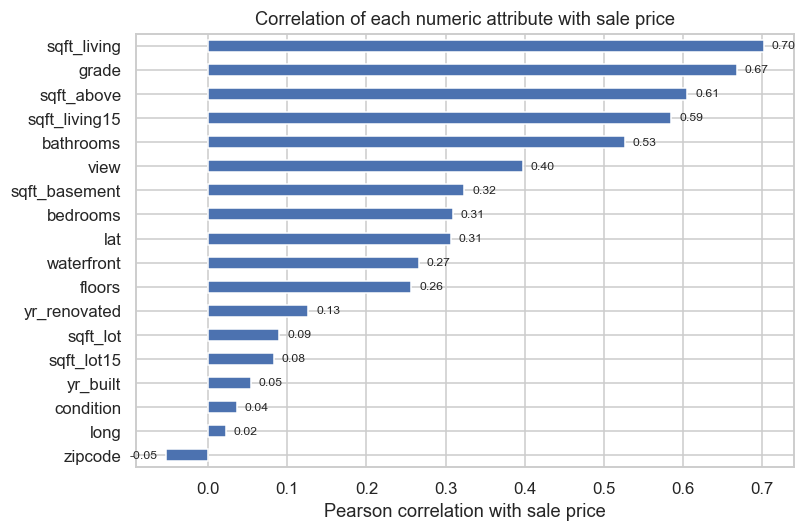

In [4]:
numeric = df.select_dtypes(include=[np.number])
corr = numeric.corr()["price"].drop("price").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5))
corr.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Pearson correlation with sale price")
ax.set_title("Correlation of each numeric attribute with sale price")
for i, value in enumerate(corr.values):
    ax.text(value + (0.01 if value >= 0 else -0.01), i, f"{value:.2f}",
            va="center", ha="left" if value >= 0 else "right", fontsize=8)
plt.tight_layout()
plt.savefig("images/fig1_correlation_with_price.png", bbox_inches="tight")
plt.show()


Living area dominates (r = 0.70), followed by grade (0.67), above-ground area
(0.61) and the living area of the fifteen nearest neighbours (0.59). Bathrooms
(0.53) and view (0.40) come next. Latitude, a proxy for location, reaches 0.31,
while lot size and year built are almost unrelated to price.

Several of these columns measure the same underlying idea (floor space), so
their correlations overlap and cannot be added together as if they were
independent effects.


## 5. Waterfront: rare, expensive

Waterfront status is a binary attribute, so a boxplot is more informative than a
correlation coefficient.


waterfront
0    21434
1      163

Median price by waterfront status (USD):
waterfront
0     450000.0
1    1400000.0


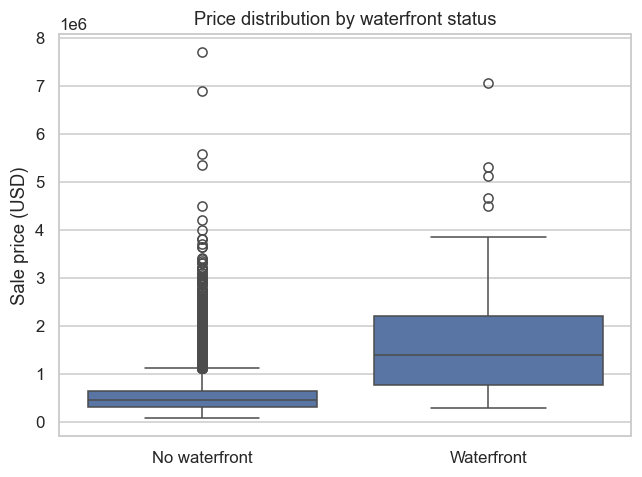

In [5]:
print(df["waterfront"].value_counts().to_string())
print("\nMedian price by waterfront status (USD):")
print(df.groupby("waterfront")["price"].median().round(0).to_string())

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(x="waterfront", y="price", data=df, ax=ax)
ax.set_xticks([0, 1], labels=["No waterfront", "Waterfront"])
ax.set_xlabel("")
ax.set_ylabel("Sale price (USD)")
ax.set_title("Price distribution by waterfront status")
plt.tight_layout()
plt.savefig("images/fig2_waterfront_price.png", bbox_inches="tight")
plt.show()


Only 163 of the 21,597 sales are waterfront properties (0.8%), but their median
price is 1,400,000 USD against 450,000 USD for everything else, a 3.1x premium.
The boxplot also shows a much wider spread and several high outliers in the
waterfront group, which matters when a model tries to estimate one coefficient
for this variable.


## 6. Size and grade

The two strongest predictors deserve a closer look: living area as a continuous
variable, and grade as an ordered categorical one.


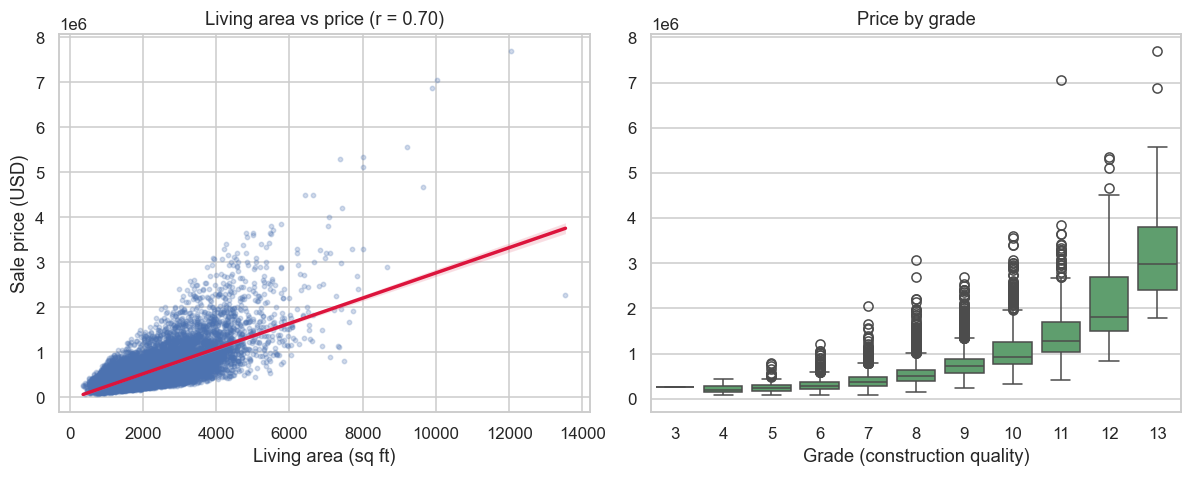

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.regplot(x="sqft_living", y="price", data=df, ax=axes[0],
            scatter_kws={"alpha": 0.25, "s": 8},
            line_kws={"color": "crimson"})
axes[0].set_xlabel("Living area (sq ft)")
axes[0].set_ylabel("Sale price (USD)")
axes[0].set_title("Living area vs price (r = 0.70)")

sns.boxplot(x="grade", y="price", data=df, ax=axes[1], color="#55A868")
axes[1].set_xlabel("Grade (construction quality)")
axes[1].set_ylabel("")
axes[1].set_title("Price by grade")

plt.tight_layout()
plt.savefig("images/fig3_size_and_grade.png", bbox_inches="tight")
plt.show()


Living area shows a clear positive relationship, but the spread widens as houses
get larger: large homes sell anywhere from roughly 500,000 to over 3,000,000 USD.
Area alone cannot pin down a price. Grade separates the market more sharply:
the median price rises from about 375,000 USD at grade 7 to 914,000 USD at
grade 10 and 1,284,000 USD at grade 11.


## 7. From description to prediction

Three models are compared: a single-feature baseline, a linear model on eleven
attributes, and two regularised variants evaluated on a held-out test set.


In [7]:
features = ["floors", "waterfront", "lat", "bedrooms", "sqft_basement",
            "view", "bathrooms", "sqft_living15", "sqft_above", "grade",
            "sqft_living"]

X = df[features]
y = df["price"]

single = LinearRegression().fit(df[["sqft_living"]], y)
print(f"R2, single feature (sqft_living), in-sample: "
      f"{single.score(df[['sqft_living']], y):.3f}")

multi = LinearRegression().fit(X, y)
print(f"R2, eleven features, in-sample: {multi.score(X, y):.3f}")


R2, single feature (sqft_living), in-sample: 0.493
R2, eleven features, in-sample: 0.658


A single feature already explains 49% of the variance in price, and the
eleven-feature model raises that to 66%. Both numbers are measured on the same
rows used for fitting, however, so they flatter the models. The honest test is a
held-out split.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=1)

ridge = Ridge(alpha=0.1).fit(X_train, y_train)
y_pred = ridge.predict(X_test)
print(f"R2, ridge on held-out test set: {r2_score(y_test, y_pred):.3f}")

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.fit_transform(X_test)

ridge_poly = Ridge(alpha=0.1).fit(X_train_poly, y_train)
y_pred_poly = ridge_poly.predict(X_test_poly)
print(f"R2, degree-2 polynomial ridge on held-out test set: "
      f"{r2_score(y_test, y_pred_poly):.3f}")
print("Features after the polynomial expansion:", X_train_poly.shape[1])


R2, ridge on held-out test set: 0.674
R2, degree-2 polynomial ridge on held-out test set: 0.688
Features after the polynomial expansion: 77


On the 15% held-out set, ridge reaches R2 = 0.67 and the degree-2 expansion
reaches R2 = 0.69. The polynomial model gains only two points while expanding
eleven features into 77, a strong hint that most of the extra flexibility fits
noise rather than signal. Cross-validation and a regularisation sweep would be
needed before claiming the more complex model is better.


## 8. Predicted versus actual

Plotting held-out predictions against the true prices shows where the model
fails, not just how often.


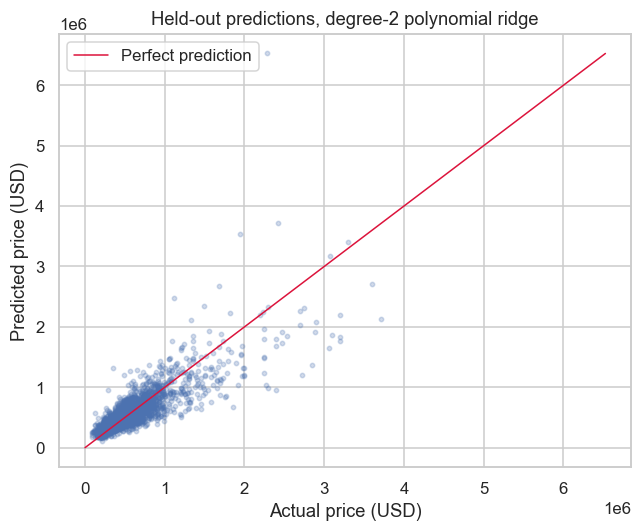

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, y_pred_poly, alpha=0.25, s=8)
lims = [0, max(y_test.max(), y_pred_poly.max())]
ax.plot(lims, lims, color="crimson", linewidth=1, label="Perfect prediction")
ax.set_xlabel("Actual price (USD)")
ax.set_ylabel("Predicted price (USD)")
ax.set_title("Held-out predictions, degree-2 polynomial ridge")
ax.legend()
plt.tight_layout()
plt.savefig("images/fig4_predicted_vs_actual.png", bbox_inches="tight")
plt.show()


The model tracks the middle of the market but compresses the extremes: very
expensive houses are under-predicted and the cheapest are over-predicted. That
regression-to-the-mean pattern is expected for a skewed target with a
squared-error loss, and it explains why the single R2 number hides a lot of
structure.


## 9. Findings

1. **Living area is the strongest single signal** (r = 0.70). On its own it
   explains 49% of the variance in sale price.
2. **Waterfront status carries a large premium.** The 163 waterfront sales have a
   median price of 1.4 million USD against 450,000 USD for the rest.
3. **Grade separates the market cleanly.** Median price rises from about 375,000
   USD at grade 7 to 1.28 million USD at grade 11.
4. **Eleven attributes reach R2 = 0.66 in-sample and 0.67 on held-out data.**
5. **The degree-2 polynomial model adds little** (0.69 on held-out data) while
   multiplying the feature count, so the simpler model is the better default.


## 10. Limitations

- The data covers one county in 2014-2015. Prices are not adjusted for inflation
  and the relationships may not transfer to another market or another year.
- The analysis is observational. It describes association, not causation, and
  the size variables overlap heavily, so individual coefficients are hard to
  read as "the effect of one extra square foot".
- No outlier treatment was applied: a handful of sales above 3 million USD
  dominate the squared error, and the R2 values are sensitive to them.
- Hyperparameters (the ridge strength, the polynomial degree) were fixed by
  hand. Cross-validation and a proper search would be needed for a defensible
  choice.
- The model ignores date and season, renovation quality, school district and
  other unobserved factors that buyers clearly pay for.

## Reproducing the analysis

```bash
pip install -r requirements.txt
jupyter notebook house_price_analysis.ipynb
```

The data downloads automatically; the four figures are written to `images/`.
